# Phase 3 Expansion: Forward Value Score (FVS)
## Airline Loyalty Disengagement Project

**Author:** Sora | **Date:** May 2026

This notebook extends Phase 3 with the Forward Value Score — our concrete answer to the brief's
challenge to interrogate whether historical CLV tells the full story.

**The question FVS answers:** "How much value do we expect this member to generate over the next
6 months, given their behavior, trajectory, and likelihood of staying?"

**Formula:**

    FVS = (pts_6mo × $0.20) × TrendBoost × (1 − P_churn)

Where:
- `pts_6mo` = points accumulated in the last 6 months (recomputed from panel)
- `$0.20` = dollar-per-point calibration, computed from the data
- `TrendBoost` = 1.0 + (trend_flights_diff / 20), clipped to [0.5, 1.5]
- `P_churn` = LightGBM tuned model's predicted churn probability (from v2 notebook output)

**Inputs:**
- `panel_cleaned.csv` (for points calculation)
- `labeled_features_lean.csv` (for trend and demographics)
- `lgbm_test_predictions_v2.csv` (your LightGBM predictions from the v2 notebook)

**Outputs:**
- `member_fvs.csv` — per-member FVS for the Jul 2018 test cohort
- Several diagnostic plots and gap-analysis tables


## 1. Setup and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = "../data/processed"
OUT_DIR  = "../data/processed"

panel    = pd.read_csv(f"{DATA_DIR}/panel_cleaned.csv", parse_dates=['flight_date','enroll_date','cancel_date'])
features = pd.read_csv(f"{DATA_DIR}/labeled_features_lean.csv", parse_dates=['as_of_date'])
preds    = pd.read_csv(f"{DATA_DIR}/lgbm_test_predictions_v2.csv", parse_dates=['as_of_date'])
loyalty  = pd.read_csv(f"{DATA_DIR}/loyalty_cleaned.csv", parse_dates=['enroll_date','cancel_date'])

print(f"Panel: {panel.shape}")
print(f"Features: {features.shape}")
print(f"LightGBM predictions: {preds.shape}")
print(f"Loyalty: {loyalty.shape}")


Panel: (302203, 11)
Features: (22759, 16)
LightGBM predictions: (11834, 4)
Loyalty: (16737, 19)


## 2. Calibrate the dollar-per-point constant from data

In [2]:
# Calibration approach: among RECENT enrollees (enrolled 2017+), CLV is approximately
# their total flying value during 2017-2018 (since that's most of their member tenure).
# This gives us a clean $/point conversion.
total_pts = panel.groupby('Loyalty Number')['Points Accumulated'].sum()
recent_members_ids = loyalty[loyalty['Enrollment Year'] >= 2017]['Loyalty Number']
recent_calib = loyalty[['Loyalty Number','CLV']].set_index('Loyalty Number').join(total_pts.rename('total_pts'))
recent_calib = recent_calib.loc[recent_calib.index.isin(recent_members_ids)]
recent_calib = recent_calib.dropna(subset=['total_pts'])
recent_calib = recent_calib[recent_calib['total_pts']>0]
recent_calib['dollar_per_point'] = recent_calib['CLV'] / recent_calib['total_pts']

DOLLAR_PER_POINT = recent_calib['dollar_per_point'].median()
print(f"Members used for calibration: {len(recent_calib):,} (enrolled 2017+)")
print(f"$/point distribution (median): ${DOLLAR_PER_POINT:.4f}")
print(f"  10th percentile: ${recent_calib['dollar_per_point'].quantile(0.10):.4f}")
print(f"  90th percentile: ${recent_calib['dollar_per_point'].quantile(0.90):.4f}")
print(f"\nInterpretation: 1,000 points ≈ ${DOLLAR_PER_POINT*1000:.2f}")


Members used for calibration: 5,048 (enrolled 2017+)
$/point distribution (median): $0.1976
  10th percentile: $0.0511
  90th percentile: $1.1578

Interpretation: 1,000 points ≈ $197.56


## 3. Compute FVS for the test cohort (Jul 2018 as-of)

In [3]:
# Restrict to test snapshot
ASOF = pd.Timestamp("2018-07-01")
LB_MONTHS = 6
lb_start = ASOF - pd.DateOffset(months=LB_MONTHS)

# pts_6mo: points accumulated in Jan-Jun 2018 per member
lb_panel = panel[(panel['flight_date'] >= lb_start) & (panel['flight_date'] < ASOF)]
pts_6mo = lb_panel.groupby('Loyalty Number')['Points Accumulated'].sum()

# Test cohort + LightGBM predictions
test = features[features['as_of_date'] == ASOF].copy()
test = test.merge(preds[['Loyalty Number','lgbm_proba']], on='Loyalty Number')
test['pts_6mo'] = test['Loyalty Number'].map(pts_6mo).fillna(0)
test = test.merge(loyalty[['Loyalty Number','CLV','Loyalty Card','Salary_Band']],
                   on='Loyalty Number', suffixes=('','_loy'))

# Trend boost
test['trend_boost'] = (1.0 + test['trend_flights_diff']/20).clip(0.5, 1.5)

# FVS
test['fvs'] = (test['pts_6mo'] * DOLLAR_PER_POINT) * test['trend_boost'] * (1 - test['lgbm_proba'])

# Components for transparency
test['fvs_base_dollars'] = test['pts_6mo'] * DOLLAR_PER_POINT
test['retention_probability'] = 1 - test['lgbm_proba']

print(f"Test cohort: {len(test):,} members")
print(f"\nFVS distribution:")
print(test['fvs'].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2))
print(f"\nCLV (lifetime, raw) distribution for comparison:")
print(test['CLV'].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2))


Test cohort: 11,834 members

FVS distribution:
count    11834.00
mean      2764.03
std       1596.89
min         99.44
10%        957.19
25%       1569.76
50%       2483.50
75%       3682.95
90%       4946.07
95%       5768.41
99%       7456.68
max      12793.92
Name: fvs, dtype: float64

CLV (lifetime, raw) distribution for comparison:
count    11834.00
mean      7942.74
std       6699.34
min       1898.01
10%       2659.99
25%       3967.44
50%       5773.90
75%       8971.77
90%      15216.94
95%      21850.52
99%      35506.98
max      74228.52
Name: CLV, dtype: float64


## 4. Distribution comparison — FVS vs CLV

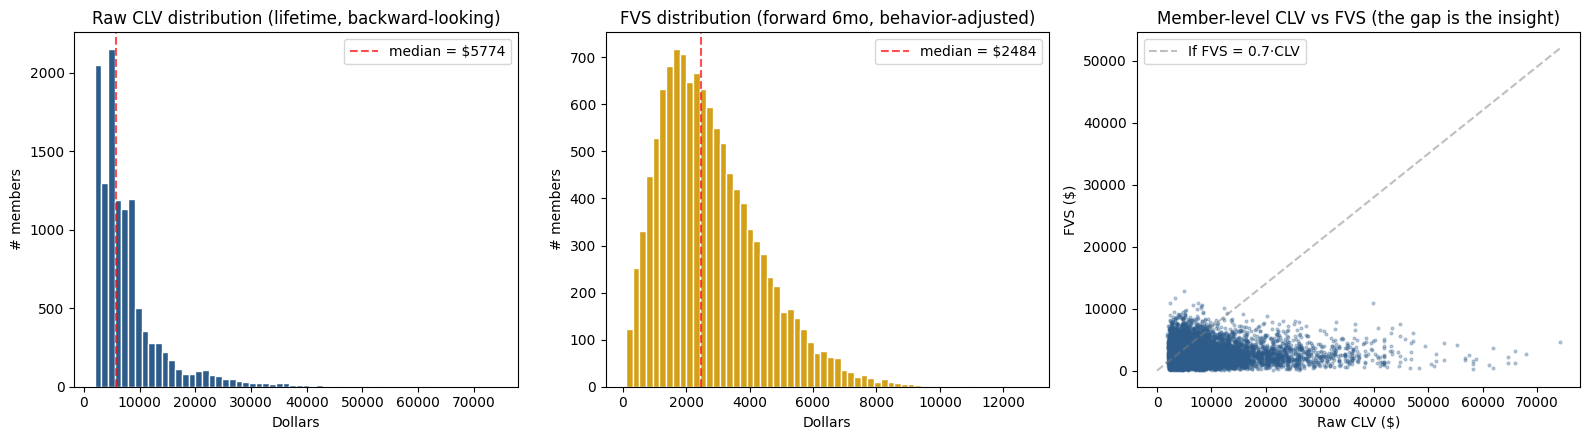

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# CLV histogram
axes[0].hist(test['CLV'], bins=60, color='#2E5C8A', edgecolor='white')
axes[0].set_title('Raw CLV distribution (lifetime, backward-looking)')
axes[0].set_xlabel('Dollars'); axes[0].set_ylabel('# members')
axes[0].axvline(test['CLV'].median(), color='red', linestyle='--', alpha=0.7, label=f"median = ${test['CLV'].median():.0f}")
axes[0].legend()

# FVS histogram
axes[1].hist(test['fvs'], bins=60, color='#D4A017', edgecolor='white')
axes[1].set_title('FVS distribution (forward 6mo, behavior-adjusted)')
axes[1].set_xlabel('Dollars'); axes[1].set_ylabel('# members')
axes[1].axvline(test['fvs'].median(), color='red', linestyle='--', alpha=0.7, label=f"median = ${test['fvs'].median():.0f}")
axes[1].legend()

# CLV vs FVS scatter — the gap
axes[2].scatter(test['CLV'], test['fvs'], s=4, alpha=0.3, color='#2E5C8A')
axes[2].plot([0, test['CLV'].max()], [0, test['CLV'].max()*0.7], color='gray', linestyle='--', alpha=0.5, label='If FVS = 0.7·CLV')
axes[2].set_xlabel('Raw CLV ($)'); axes[2].set_ylabel('FVS ($)')
axes[2].set_title('Member-level CLV vs FVS (the gap is the insight)')
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fvs_distributions.png", dpi=110, bbox_inches='tight')
plt.show()


## 5. Surface the "gap" members — where FVS and CLV disagree

These are members the airline's existing CLV reporting cannot find.

**Ghost-value veterans** = high CLV but low FVS. Their historical value is locked in, but
they will not generate much going forward. Marketing dollars spent on them are wasted.

**Undervalued risers** = low CLV but high FVS. They're either newer members building momentum
or moderate-tenure members in a growth phase. Marketing currently underweights them because
they look small in CLV reports.

In [5]:
# Define "high" and "low" as top and bottom quartiles
clv_q75 = test['CLV'].quantile(0.75)
clv_q25 = test['CLV'].quantile(0.25)
fvs_q75 = test['fvs'].quantile(0.75)
fvs_q25 = test['fvs'].quantile(0.25)

# Ghost-value: top-quartile CLV but bottom-quartile FVS
ghost = test[(test['CLV'] >= clv_q75) & (test['fvs'] <= fvs_q25)]
# Undervalued risers: bottom-quartile CLV but top-quartile FVS
risers = test[(test['CLV'] <= clv_q25) & (test['fvs'] >= fvs_q75)]

print(f"Ghost-value veterans (high CLV, low FVS): {len(ghost):,} members")
print(f"  avg raw CLV: ${ghost['CLV'].mean():,.0f}")
print(f"  avg FVS:     ${ghost['fvs'].mean():,.0f}")
print(f"  avg recency since flight: {ghost['rec_months_since_flight'].mean():.2f} months")
print(f"  avg trend (flights diff): {ghost['trend_flights_diff'].mean():.2f}")
print(f"  avg P(churn): {ghost['lgbm_proba'].mean():.3f}")
print(f"  avg tenure: {ghost['demo_tenure_months'].mean():.1f} months")

print(f"\nUndervalued risers (low CLV, high FVS): {len(risers):,} members")
print(f"  avg raw CLV: ${risers['CLV'].mean():,.0f}")
print(f"  avg FVS:     ${risers['fvs'].mean():,.0f}")
print(f"  avg recency since flight: {risers['rec_months_since_flight'].mean():.2f} months")
print(f"  avg trend (flights diff): {risers['trend_flights_diff'].mean():.2f}")
print(f"  avg P(churn): {risers['lgbm_proba'].mean():.3f}")
print(f"  avg tenure: {risers['demo_tenure_months'].mean():.1f} months")


Ghost-value veterans (high CLV, low FVS): 741 members
  avg raw CLV: $16,564
  avg FVS:     $1,010
  avg recency since flight: 2.49 months
  avg trend (flights diff): -0.93
  avg P(churn): 0.022
  avg tenure: 39.3 months

Undervalued risers (low CLV, high FVS): 746 members
  avg raw CLV: $2,929
  avg FVS:     $4,963
  avg recency since flight: 1.07 months
  avg trend (flights diff): 4.31
  avg P(churn): 0.016
  avg tenure: 40.7 months


## 6. FVS by segment — does the segmentation align with forward value?

In [6]:
# Load segment assignments (from your v2 notebook output)
seg_assign = pd.read_csv(f"{DATA_DIR}/segmentation_assignments_v2.csv")
test_seg = test.merge(seg_assign[['Loyalty Number','segment']], on='Loyalty Number')

seg_fvs = test_seg.groupby('segment').agg(
    n=('Loyalty Number','count'),
    avg_clv=('CLV','mean'),
    avg_fvs=('fvs','mean'),
    median_fvs=('fvs','median'),
    avg_p_churn=('lgbm_proba','mean'),
    avg_recency=('rec_months_since_flight','mean'),
    avg_trend=('trend_flights_diff','mean'),
).round(2)
seg_fvs['fvs_to_clv_ratio'] = (seg_fvs['avg_fvs'] / seg_fvs['avg_clv']).round(3)
print("=== SEGMENT × FVS PROFILE ===")
print(seg_fvs.to_string())

print("\nReading guide:")
print("  fvs_to_clv_ratio > 0.5: segment is forward-value heavy (worth investing in)")
print("  fvs_to_clv_ratio < 0.2: segment is past-value heavy (low retention ROI)")


=== SEGMENT × FVS PROFILE ===
            n  avg_clv  avg_fvs  median_fvs  avg_p_churn  avg_recency  avg_trend  fvs_to_clv_ratio
segment                                                                                           
0         414  8569.09   926.01      850.79         0.02         2.26       0.17             0.108
1        3932  8007.23  2825.58     2678.62         0.01         1.28       0.27             0.353
2        1840  8070.41  1238.88     1193.54         0.03         3.32      -2.46             0.154
3        2815  7929.84  4222.29     4059.80         0.02         1.11       5.21             0.532
4        2833  7691.59  2488.79     2271.60         0.02         1.36       1.71             0.324

Reading guide:
  fvs_to_clv_ratio > 0.5: segment is forward-value heavy (worth investing in)
  fvs_to_clv_ratio < 0.2: segment is past-value heavy (low retention ROI)


## 7. Save the FVS column for downstream use (prototype, recommendations)

In [7]:
out = test_seg[['Loyalty Number','as_of_date','CLV','pts_6mo','trend_flights_diff',
                  'lgbm_proba','retention_probability','trend_boost',
                  'fvs_base_dollars','fvs','segment','Loyalty Card','Salary_Band']]
out.to_csv(f"{OUT_DIR}/member_fvs.csv", index=False)
print(f"Saved member_fvs.csv ({len(out):,} rows)")

# Summary card
print("\n" + "="*68)
print("  PHASE 3 EXPANSION — FVS SUMMARY")
print("="*68)
print(f"\nCalibration: $/point = ${DOLLAR_PER_POINT:.4f}")
print(f"Test cohort size: {len(test):,}")
print(f"\nMedian raw CLV (lifetime, backward): ${test['CLV'].median():,.0f}")
print(f"Median FVS (forward 6mo):           ${test['fvs'].median():,.0f}")
print(f"\nGhost-value veterans (high CLV, low FVS): {len(ghost):,}")
print(f"Undervalued risers (low CLV, high FVS):   {len(risers):,}")
print(f"\nSegment with highest FVS:  {seg_fvs['avg_fvs'].idxmax()} (avg ${seg_fvs['avg_fvs'].max():,.0f})")
print(f"Segment with lowest FVS:   {seg_fvs['avg_fvs'].idxmin()} (avg ${seg_fvs['avg_fvs'].min():,.0f})")


Saved member_fvs.csv (11,834 rows)

  PHASE 3 EXPANSION — FVS SUMMARY

Calibration: $/point = $0.1976
Test cohort size: 11,834

Median raw CLV (lifetime, backward): $5,774
Median FVS (forward 6mo):           $2,484

Ghost-value veterans (high CLV, low FVS): 741
Undervalued risers (low CLV, high FVS):   746

Segment with highest FVS:  3 (avg $4,222)
Segment with lowest FVS:   0 (avg $926)
